In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/Project1WeatherDataset.csv')

In [ ]:
print(df.shape)

(8784, 8)


In [ ]:
print(df.dtypes)

Date/Time            object
Temp_C              float64
Dew Point Temp_C    float64
Rel Hum_%             int64
Wind Speed_km/h       int64
Visibility_km       float64
Press_kPa           float64
Weather              object
dtype: object


In [ ]:
print(df.describe())

            Temp_C  Dew Point Temp_C    Rel Hum_%  Wind Speed_km/h  \
count  8784.000000       8784.000000  8784.000000      8784.000000   
mean      8.798144          2.555294    67.431694        14.945469   
std      11.687883         10.883072    16.918881         8.688696   
min     -23.300000        -28.500000    18.000000         0.000000   
25%       0.100000         -5.900000    56.000000         9.000000   
50%       9.300000          3.300000    68.000000        13.000000   
75%      18.800000         11.800000    81.000000        20.000000   
max      33.000000         24.400000   100.000000        83.000000   

       Visibility_km    Press_kPa  
count    8784.000000  8784.000000  
mean       27.664447   101.051623  
std        12.622688     0.844005  
min         0.200000    97.520000  
25%        24.100000   100.560000  
50%        25.000000   101.070000  
75%        25.000000   101.590000  
max        48.300000   103.650000  


In [ ]:
df['Date/Time'] = pd.to_datetime(df['Date/Time'])

In [ ]:
print(f"\nFirst Date: {df['Date/Time'].min()}")


First Date: 2012-01-01 00:00:00


In [ ]:
print(f"Last Date: {df['Date/Time'].max()}")
print("Note: This dataset represents hourly weather data for a single location over a year, so country/place count is 1.")

Last Date: 2012-12-31 23:00:00
Note: This dataset represents hourly weather data for a single location over a year, so country/place count is 1.


In [ ]:
df_analysis = df.copy()

In [ ]:
# Count missing values per column
missing_values = df_analysis.isnull().sum()
print("Missing Values Count:\n", missing_values)

Missing Values Count:
 Date/Time           0
Temp_C              0
Dew Point Temp_C    0
Rel Hum_%           0
Wind Speed_km/h     0
Visibility_km       0
Press_kPa           0
Weather             0
dtype: int64


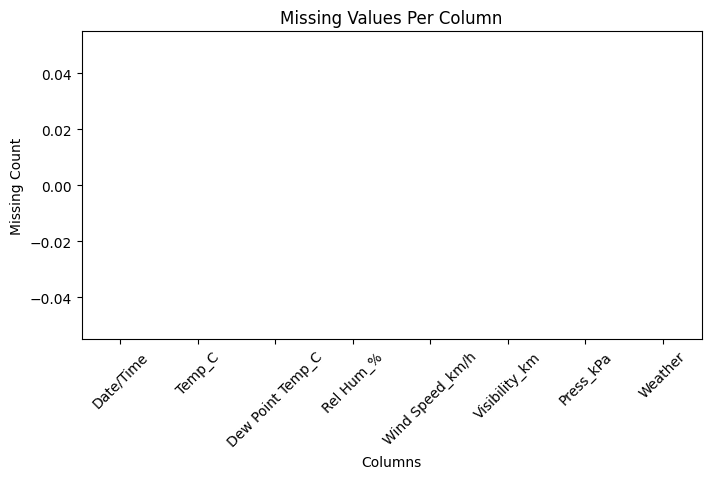

In [ ]:
# Show missing values in a graph
plt.figure(figsize=(8, 4))
sns.barplot(x=missing_values.index, y=missing_values.values, palette='viridis', hue=missing_values.index, legend=False)
plt.title("Missing Values Per Column")
plt.xlabel("Columns")
plt.ylabel("Missing Count")
plt.xticks(rotation=45)
plt.show()

In [ ]:
# Decision on missing values:
# Since there are 0 missing values across all columns, no dropping or filling is required.
print("Decision: No missing values found in the dataset, so no filling or dropping actions are needed.")

Decision: No missing values found in the dataset, so no filling or dropping actions are needed.


In [ ]:
# Count duplicate rows
duplicate_count = df_analysis.duplicated().sum()
print(f"Total Duplicate Rows: {duplicate_count}")

Total Duplicate Rows: 0


In [ ]:
# Check if any date/time appears more than once
date_counts = df_analysis['Date/Time'].value_counts()
duplicates_dates = date_counts[date_counts > 1]

if duplicates_dates.empty:
    print("No duplicates found: Each date/time timestamp appears exactly once.")
else:
    print(f"Found {len(duplicates_dates)} duplicate timestamps. Removing them...")
    df_analysis = df_analysis.drop_duplicates(subset=['Date/Time'])

print("Proof - Total rows after duplicate check:", len(df_analysis))

No duplicates found: Each date/time timestamp appears exactly once.
Proof - Total rows after duplicate check: 8784


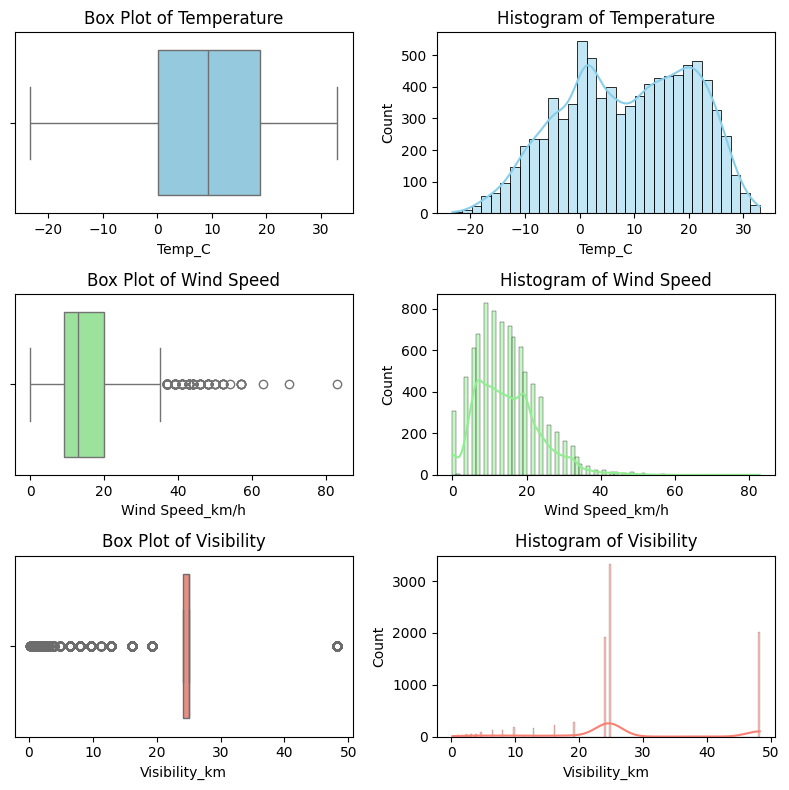

In [ ]:
# Box plots and histograms for Temp_C, Wind Speed_km/h, and Visibility_km
fig, axes = plt.subplots(3, 2, figsize=(8, 8))
# Temperature
sns.boxplot(x=df_analysis['Temp_C'], ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Box Plot of Temperature')
sns.histplot(df_analysis['Temp_C'], kde=True, ax=axes[0, 1], color='skyblue')
axes[0, 1].set_title('Histogram of Temperature')

# Wind Speed
sns.boxplot(x=df_analysis['Wind Speed_km/h'], ax=axes[1, 0], color='lightgreen')
axes[1, 0].set_title('Box Plot of Wind Speed')
sns.histplot(df_analysis['Wind Speed_km/h'], kde=True, ax=axes[1, 1], color='lightgreen')
axes[1, 1].set_title('Histogram of Wind Speed')

# Visibility
sns.boxplot(x=df_analysis['Visibility_km'], ax=axes[2, 0], color='salmon')
axes[2, 0].set_title('Box Plot of Visibility')
sns.histplot(df_analysis['Visibility_km'], kde=True, ax=axes[2, 1], color='salmon')
axes[2, 1].set_title('Histogram of Visibility')

plt.tight_layout()
plt.show()

In [ ]:
# IQR Rule on Wind Speed
Q1 = df_analysis['Wind Speed_km/h'].quantile(0.25)
Q3 = df_analysis['Wind Speed_km/h'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR
extreme_wind = df_analysis[df_analysis['Wind Speed_km/h'] > upper_bound]
print(f"Number of high wind outliers using IQR: {len(extreme_wind)}")
print("Note: High wind speed values represent natural weather phenomena like strong winds or storms, so they are real readings and should not be removed.")

Number of high wind outliers using IQR: 162
Note: High wind speed values represent natural weather phenomena like strong winds or storms, so they are real readings and should not be removed.


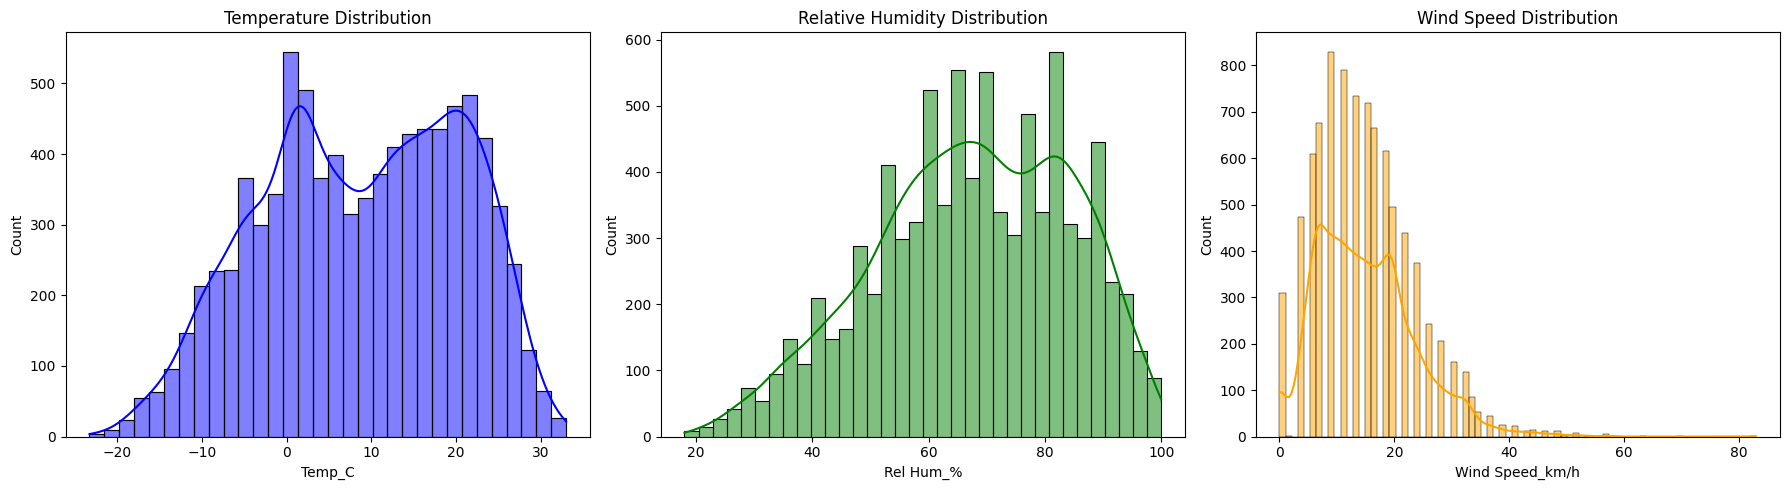

Typical Values (Median/Mean):
Temperature - Mean: 8.80°C, Median: 9.30°C
Humidity - Mean: 67.43%, Median: 68.00%
Wind Speed - Mean: 14.95 km/h, Median: 13.00 km/h


In [ ]:
# One graph for each key weather column & summary stats
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df_analysis['Temp_C'], kde=True, ax=axes[0], color='blue')
axes[0].set_title('Temperature Distribution')

sns.histplot(df_analysis['Rel Hum_%'], kde=True, ax=axes[1], color='green')
axes[1].set_title('Relative Humidity Distribution')

sns.histplot(df_analysis['Wind Speed_km/h'], kde=True, ax=axes[2], color='orange')
axes[2].set_title('Wind Speed Distribution')

plt.tight_layout()
plt.show()

print("Typical Values (Median/Mean):")
print(f"Temperature - Mean: {df_analysis['Temp_C'].mean():.2f}°C, Median: {df_analysis['Temp_C'].median():.2f}°C")
print(f"Humidity - Mean: {df_analysis['Rel Hum_%'].mean():.2f}%, Median: {df_analysis['Rel Hum_%'].median():.2f}%")
print(f"Wind Speed - Mean: {df_analysis['Wind Speed_km/h'].mean():.2f} km/h, Median: {df_analysis['Wind Speed_km/h'].median():.2f} km/h")

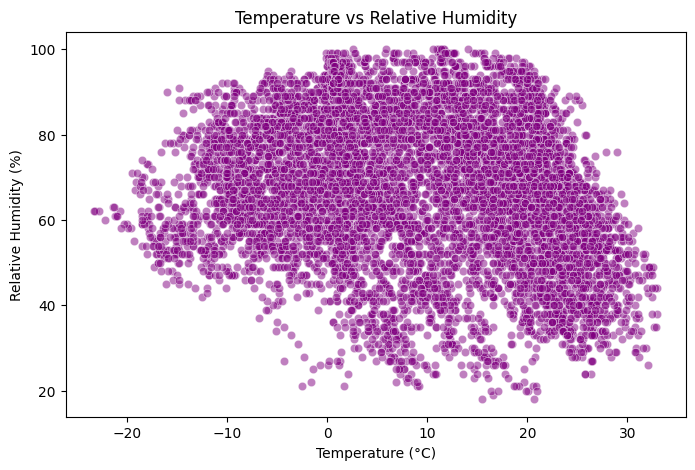

In [ ]:
# 1. Scatter plot of two weather columns
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_analysis, x='Temp_C', y='Rel Hum_%', alpha=0.5, color='purple')
plt.title('Temperature vs Relative Humidity')
plt.xlabel('Temperature (°C)')
plt.ylabel('Relative Humidity (%)')
plt.show()

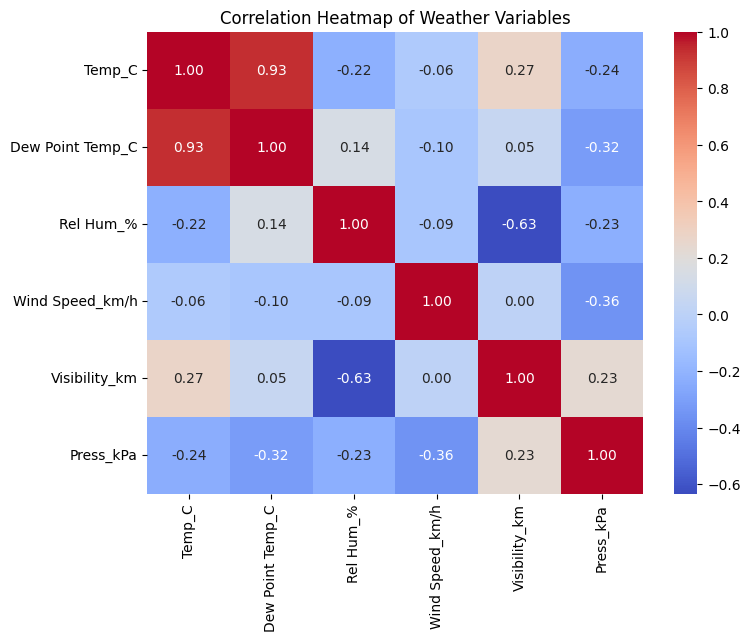

In [ ]:
# 2. Correlation heatmap
plt.figure(figsize=(8, 6))
numeric_cols = df_analysis.select_dtypes(include=[np.number]).columns
sns.heatmap(df_analysis[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Weather Variables')
plt.show()

/tmp/ipykernel_2481/3637842787.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df_analysis.set_index('Date/Time')['Temp_C'].resample('M').mean().plot(marker='o', color='b')


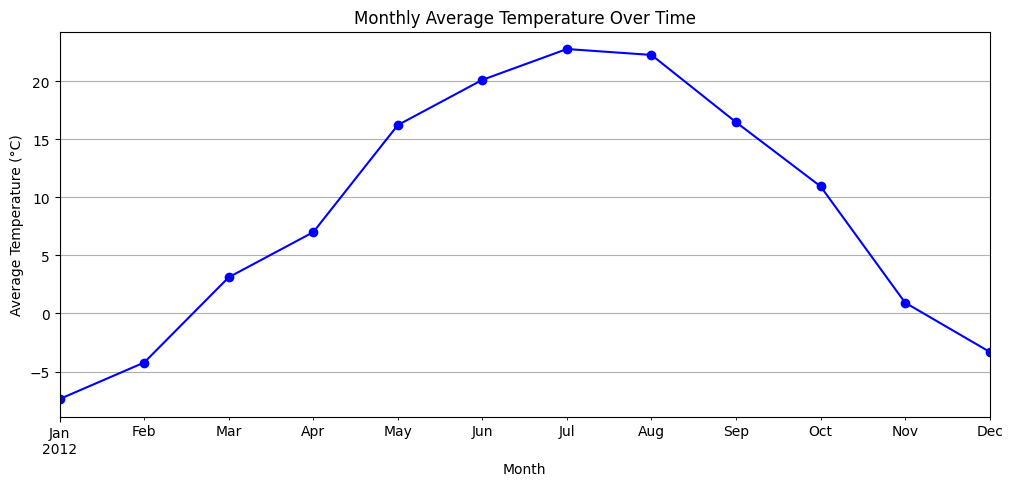

In [ ]:
# 3. Line chart of temperature over time (Resampled monthly mean for clarity)
plt.figure(figsize=(12, 5))
df_analysis.set_index('Date/Time')['Temp_C'].resample('M').mean().plot(marker='o', color='b')
plt.title('Monthly Average Temperature Over Time')
plt.xlabel('Month')
plt.ylabel('Average Temperature (°C)')
plt.grid(True)
plt.show()

# Q1: How is temperature spread across the year?

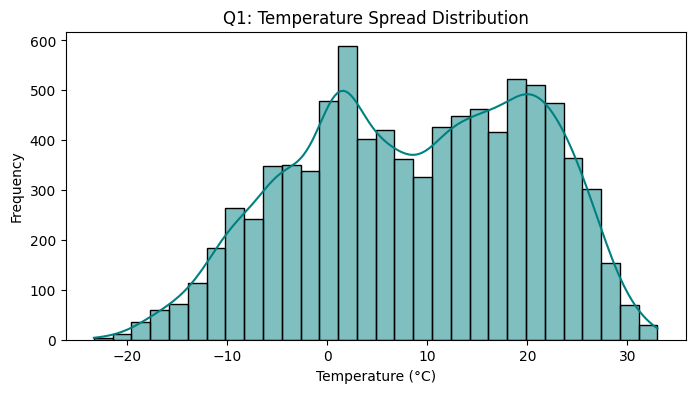

Answer 1: Temperature is distributed across a wide range from freezing sub-zero conditions up to warm summer peaks, with a mean around 8.8°C.


In [ ]:
plt.figure(figsize=(8, 4))
sns.histplot(df_analysis['Temp_C'], bins=30, kde=True, color='teal')
plt.title('Q1: Temperature Spread Distribution')
plt.xlabel('Temperature (°C)')
plt.ylabel('Frequency')
plt.show()
print("Answer 1: Temperature is distributed across a wide range from freezing sub-zero conditions up to warm summer peaks, with a mean around 8.8°C.")

# Q2: What is the distribution of wind speeds?

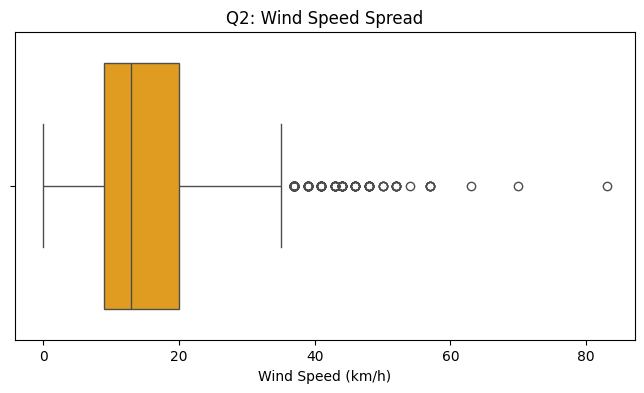

Answer 2: Most wind speeds are concentrated between 9 and 20 km/h, with higher speeds acting as upper-bound natural outliers.


In [ ]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_analysis['Wind Speed_km/h'], color='orange')
plt.title('Q2: Wind Speed Spread')
plt.xlabel('Wind Speed (km/h)')
plt.show()
print("Answer 2: Most wind speeds are concentrated between 9 and 20 km/h, with higher speeds acting as upper-bound natural outliers.")

# Q3: How frequently do different weather conditions occur?

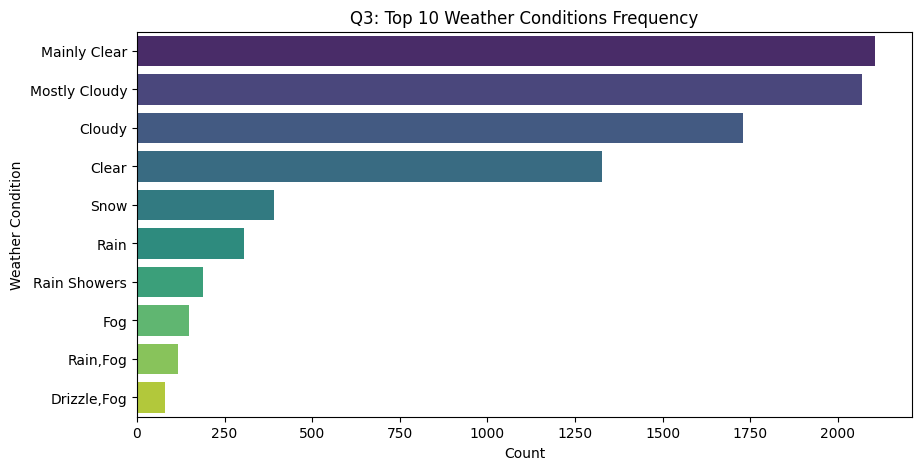

Answer 3: Clear, Maintained Cloudy, and Foggy weather conditions appear most frequently throughout the year.


In [ ]:
plt.figure(figsize=(10, 5))
top_weather = df_analysis['Weather'].value_counts().head(10)
sns.barplot(x=top_weather.values, y=top_weather.index, palette='viridis', hue=top_weather.index, legend=False)
plt.title('Q3: Top 10 Weather Conditions Frequency')
plt.xlabel('Count')
plt.ylabel('Weather Condition')
plt.show()
print("Answer 3: Clear, Maintained Cloudy, and Foggy weather conditions appear most frequently throughout the year.")

# Q4: How does relative humidity change with temperature?

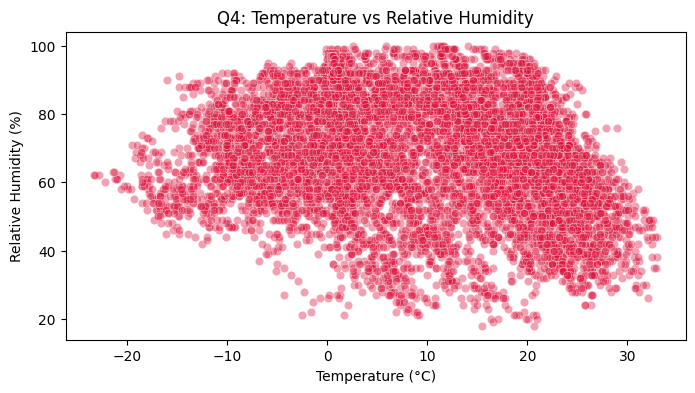

Answer 4: Lower temperatures tend to have higher and more spread out relative humidity percentages, whereas very high temperatures generally show lower minimum humidity.


In [ ]:
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df_analysis, x='Temp_C', y='Rel Hum_%', alpha=0.4, color='crimson')
plt.title('Q4: Temperature vs Relative Humidity')
plt.xlabel('Temperature (°C)')
plt.ylabel('Relative Humidity (%)')
plt.show()
print("Answer 4: Lower temperatures tend to have higher and more spread out relative humidity percentages, whereas very high temperatures generally show lower minimum humidity.")

# Q5: How does wind speed relate to visibility?

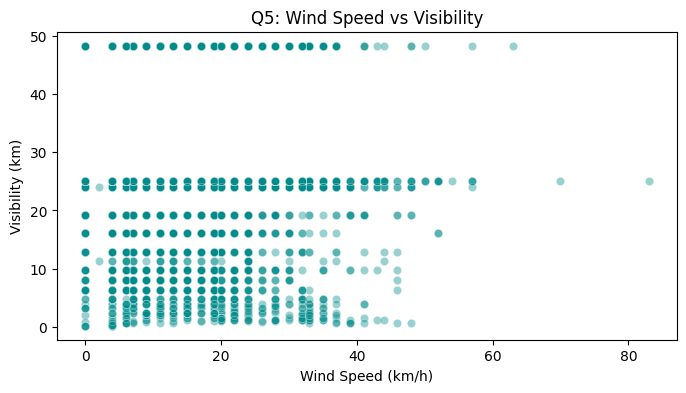

Answer 5: Higher wind speeds generally correlate with clearer air, reducing foggy low-visibility conditions and keeping visibility mostly at higher km ranges.


In [ ]:
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df_analysis, x='Wind Speed_km/h', y='Visibility_km', alpha=0.4, color='darkcyan')
plt.title('Q5: Wind Speed vs Visibility')
plt.xlabel('Wind Speed (km/h)')
plt.ylabel('Visibility (km)')
plt.show()
print("Answer 5: Higher wind speeds generally correlate with clearer air, reducing foggy low-visibility conditions and keeping visibility mostly at higher km ranges.")

Conclusion:
1. The dataset contains clean, complete hourly weather records for an entire year without any missing values or duplicate timestamps.
2. Temperature exhibits a clear seasonal cycle, moving from cold winter months to warm summer peaks.
3. Variables like temperature and humidity show distinct inverse tendencies at extreme ranges.
4. Natural outliers in wind speed and visibility accurately reflect real-world meteorological variations such as storms or fog.
5. Overall, the analysis provides a comprehensive overview of annual climate patterns at the given location.